[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch26_LabCh26_State_Space_Models.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 26: State-Space Models: From Kalman to Mamba** (Part V: Attending).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=26](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=26)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch26 - State-Space Models
## A running state with a control engineer's update rule: watch it remember, forget, explode, train in parallel, and learn to choose

This lab goes with **Chapter 26** of *The Why Book of Deep Learning*.

A state-space model (SSM) keeps a small vector of numbers, the **state**, and updates it once per step with
two matrix multiplications: `state = A·state + B·input`, then reads an answer with `output = C·state`.
No tanh inside the loop. That one restriction (the loop is *linear*) is what lets the same layer run as a
step-by-step recurrence at inference and as one big parallel computation in training. In this lab you build
the recurrence with NumPy alone, watch the eigenvalues of A decide how long it remembers, turn a continuous
system into a discrete one with a step size Δ, prove that the recurrence *is* a convolution, compute it with a
parallel scan, and then build a tiny **selective** SSM (the idea behind Mamba) that solves a memory task no
fixed SSM of any size can solve.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Run a discrete SSM by hand and use it to clean a noisy signal | Steps 2 and 3 |
| Read memory length off the eigenvalues of A (fade, hold, explode, ring) | Steps 4 to 6 |
| Discretise a continuous system with a step size Δ and explain what Δ does | Steps 7 to 9 |
| Show that a linear recurrence equals a convolution with a long kernel | Steps 10 and 11 |
| Compute a recurrence with a parallel scan in log₂(T) rounds | Step 12 |
| Build a selective SSM whose Δ depends on the input, and beat every fixed SSM | Steps 13 to 17 |
| Say exactly how much history a state of N numbers can hold | Steps 18 to 20 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** a few seconds on a laptop CPU. NumPy and Matplotlib only; nothing is downloaded and no
> TensorFlow is needed. Every model here is small enough to check by hand.

---
# Part A - The recurrence

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(26)
np.set_printoptions(precision=4, suppress=True)
print("NumPy", np.__version__)

NumPy 2.4.6


---
## Step 2 - The whole model in five lines

The state has N numbers. At every step:

* `state = A @ state + B * u`   (A is N × N, B has N numbers, u is the input at this step)
* `y = C @ state`               (C has N numbers)

We start with N = 2 and a diagonal A, so each state number is its own running average with its own
forgetting factor: 0.6 forgets fast, 0.8 forgets more slowly. B is chosen so that a constant input of 1
eventually produces a state of exactly 1 (B = 1 − a), and C averages the two.

> **Predict:** fed a constant input of 1 for 100 steps, what is y at the end? After only 1 step?

In [2]:
def ssm_run(A, B, C, u):
    """Discrete linear state-space model: x_t = A x_{t-1} + B u_t, y_t = C x_t. Returns y (and all states)."""
    N = A.shape[0]
    x = np.zeros(N)
    ys, xs = [], []
    for ut in u:
        x = A @ x + B * ut
        xs.append(x.copy())
        ys.append(C @ x)
    return np.array(ys), np.array(xs)

A = np.diag([0.6, 0.8])
B = np.array([0.4, 0.2])            # 1 - a, so a constant input settles at state = 1
C = np.array([0.5, 0.5])
y, xs = ssm_run(A, B, C, np.ones(100))
print("after 1 step   :", round(y[0], 4), " state", xs[0])
print("after 100 steps:", round(y[-1], 4), " state", xs[-1])

after 1 step   : 0.3  state [0.4 0.2]
after 100 steps: 1.0  state [1. 1.]


### Why we see this

After one step the fast lane holds 0.4 and the slow lane 0.2, so y = 0.30. Each lane closes a fixed
fraction of the gap every step (40% and 20%), so after 100 steps both have arrived at 1. Nothing
here is learnt: A, B and C are three small sets of numbers, and the whole "network" is a loop. In a real SSM
layer they are trained, and there are many such loops side by side, one set per input channel.

---
## Step 3 - Track a noisy signal

A slow sine wave buried in noise. The SSM is a smoother: it keeps a memory of recent inputs and reports a
blend of them.

> **Predict:** will the SSM's output be closer to the clean wave than the raw noisy samples are? Will it be
> early, on time or late?

mean squared error, raw samples vs clean : 0.1680
mean squared error, SSM output vs clean  : 0.0439


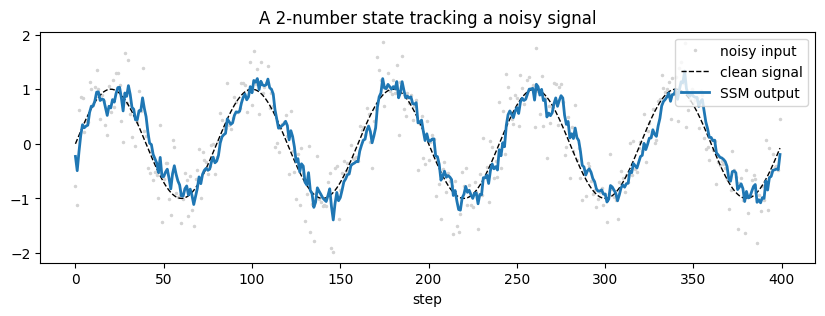

In [3]:
T = 400
t = np.arange(T)
clean = np.sin(2 * np.pi * t / 80)
noisy = clean + 0.4 * rng.normal(size=T)
y_ssm, _ = ssm_run(A, B, C, noisy)

mse = lambda a, b: float(np.mean((a - b) ** 2))
print(f"mean squared error, raw samples vs clean : {mse(noisy, clean):.4f}")
print(f"mean squared error, SSM output vs clean  : {mse(y_ssm, clean):.4f}")

plt.figure(figsize=(10, 3))
plt.plot(t, noisy, ".", ms=3, color="lightgray", label="noisy input")
plt.plot(t, clean, "k--", lw=1, label="clean signal")
plt.plot(t, y_ssm, color="tab:blue", lw=2, label="SSM output")
plt.legend(loc="upper right"); plt.xlabel("step"); plt.title("A 2-number state tracking a noisy signal")
plt.show()

### Why we see this

The error falls to about a quarter of the raw error: averaging over recent samples cancels much of the noise.
Look closely and the blue curve runs slightly **late**: an average of the past always lags. That is the
basic trade of every memory: a longer memory averages away more noise and lags more. Step 4 turns that
knob.

---
## Step 4 - One knob: how fast to forget

Replace both forgetting factors by one number a (and keep B = 1 − a).

> **Predict:** order a = 0.3, 0.7, 0.99 from best to worst at tracking this wave. Which one is too jumpy and
> which one too slow?

In [4]:
for a in [0.3, 0.5, 0.7, 0.9, 0.99]:
    A1, B1, C1 = np.array([[a]]), np.array([1 - a]), np.array([1.0])
    y1, _ = ssm_run(A1, B1, C1, noisy)
    print(f"a = {a:<5}  memory about {1 / (1 - a):6.1f} steps   error vs clean {mse(y1, clean):.4f}")

a = 0.3    memory about    1.4 steps   error vs clean 0.0884
a = 0.5    memory about    2.0 steps   error vs clean 0.0549
a = 0.7    memory about    3.3 steps   error vs clean 0.0404
a = 0.9    memory about   10.0 steps   error vs clean 0.1591
a = 0.99   memory about  100.0 steps   error vs clean 0.4829


### Why we see this

a = 0.3 remembers under 2 steps and barely smooths; a = 0.99 remembers about 100 steps, longer than the
80-step period of the wave, so it averages the wave itself away. The best a sits in between (0.7 here, about 3 steps). **The size of
the eigenvalue is the length of the memory**, and the right length depends on the signal. A trained SSM
layer learns many different memory lengths at once, one per state number.

---
## Step 5 - Impulse responses: fade, hold, explode

Feed a single 1 at step 0 and zeros afterwards, and watch how much of it is still in the state later. For a
one-number state that is aᵗ.

> **Predict:** for a = 0.9, how many steps until half the impulse is gone? For a = 0.99? For a = 1.05, how
> many steps until it has doubled?

a = 0.5   half-life    1.0 steps
a = 0.9   half-life    6.6 steps
a = 0.99  half-life   69.0 steps
a = 1.02  doubles every  35.0 steps; after 120 steps x10.8
a = 1.05  doubles every 14.2 steps


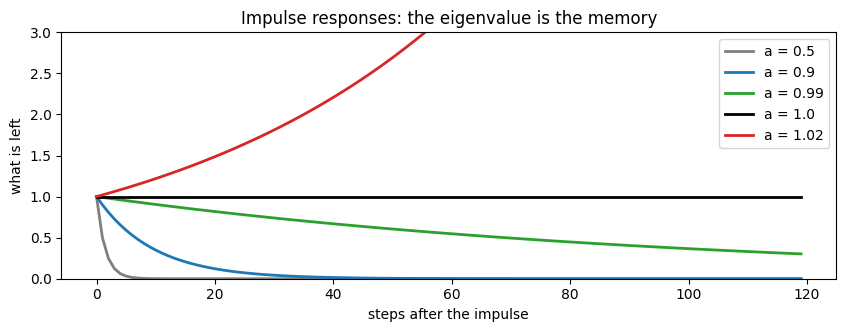

In [5]:
steps = np.arange(120)
plt.figure(figsize=(10, 3.2))
for a, c in [(0.5, "tab:gray"), (0.9, "tab:blue"), (0.99, "tab:green"), (1.0, "k"), (1.02, "tab:red")]:
    plt.plot(steps, a ** steps, color=c, lw=2, label=f"a = {a}")
    if a < 1:
        print(f"a = {a:<5} half-life {np.log(0.5) / np.log(a):6.1f} steps")
    elif a > 1:
        print(f"a = {a:<5} doubles every {np.log(2) / np.log(a):5.1f} steps; after 120 steps x{a ** 120:,.1f}")
print("a = 1.05  doubles every", round(np.log(2) / np.log(1.05), 1), "steps")
plt.ylim(0, 3); plt.legend(); plt.xlabel("steps after the impulse"); plt.ylabel("what is left")
plt.title("Impulse responses: the eigenvalue is the memory"); plt.show()

### Why we see this

Half-life = ln 0.5 / ln a: 1 step for 0.5, about 6.6 for 0.9, about 69 for 0.99. At exactly 1 nothing is
forgotten, ever (and nothing ever settles). Above 1 the impulse grows without limit: 1.05 doubles every
14.2 steps. This is the same repeated multiplication as Chapter 9's vanishing and exploding gradients, now
happening in the forward pass. Real SSMs keep every eigenvalue strictly inside the unit circle **by
construction** (Step 7 shows how), so they cannot explode, however they are trained.

---
## Step 6 - A full matrix: the eigenvalues decide, not the entries

With a non-diagonal A you cannot read the memory off the entries. Its eigenvalues still decide everything.
A rotation scaled by r has the complex eigenvalues r·e^(±iθ): the state spins as it fades, so the memory
**rings**.

> **Predict:** the matrix below has all entries smaller than 1. Is it stable?

ring  : eigenvalues [0.908+0.281j 0.908-0.281j]  |largest| = 0.950  state size after 60 steps = 0.0461
sneaky: eigenvalues [1.4 0.4]  |largest| = 1.400  state size after 60 steps = 4.14e+08


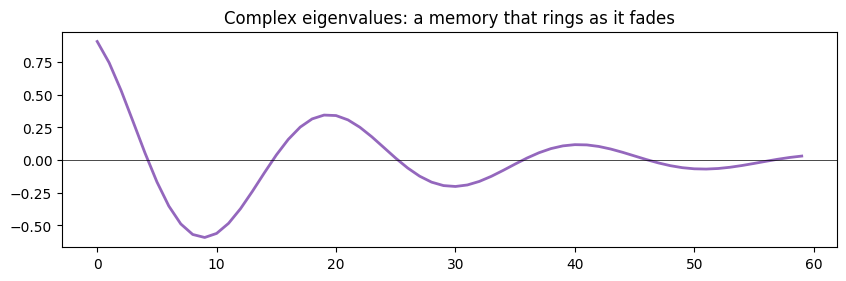

In [6]:
def show_matrix(A, name, n=60):
    lam = np.linalg.eigvals(A)
    x = np.array([1.0, 0.0]); norms = []
    for _ in range(n):
        x = A @ x; norms.append(np.linalg.norm(x))
    print(f"{name}: eigenvalues {np.round(lam, 3)}  |largest| = {np.abs(lam).max():.3f}  "
          f"state size after {n} steps = {norms[-1]:.3g}")
    return norms

r, th = 0.95, 0.3
ring = r * np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
sneaky = np.array([[0.9, 0.5], [0.5, 0.9]])
n_ring = show_matrix(ring, "ring  ")
n_sneaky = show_matrix(sneaky, "sneaky")

x = np.array([1.0, 0.0]); first = []
for _ in range(60):
    x = ring @ x; first.append(x[0])
plt.figure(figsize=(10, 2.8)); plt.plot(first, color="tab:purple", lw=2)
plt.axhline(0, color="k", lw=0.5); plt.title("Complex eigenvalues: a memory that rings as it fades"); plt.show()

### Why we see this

Every entry of `sneaky` is below 1, yet its eigenvalues are 1.4 and 0.4, and the state grows by about 1.4×
per step. Entries lie; eigenvalues do not. The ringing matrix has |eigenvalue| = 0.95, so it fades, but it
also turns by 0.3 radians per step: a damped oscillation. Many SSMs (S4 and its diagonal successors) use
complex eigenvalues on purpose, because a bank of damped oscillators at many frequencies can represent a
long, wiggly history with few numbers.

---
# Part B - From continuous time to steps

---
## Step 7 - Discretise with a step size Δ

Control engineers write SSMs in continuous time: dx/dt = a·x + b·u. A negative a means "decay towards zero
at rate |a|". To run it on tokens we pick a step size Δ and ask: if the input is held constant for Δ units of
time, where does the state end up? The exact answer (the *zero-order hold*) is

* Ā = exp(Δ·a),   B̄ = (Ā − 1)/a · b

> **Predict:** with a = −1, what is Ā for Δ = 0.01, 0.1 and 1? Roughly how many steps of memory is each?

In [7]:
def zoh(a, b, dt):
    Abar = np.exp(dt * a)
    Bbar = (Abar - 1) / a * b
    return Abar, Bbar

a_c, b_c = -1.0, 1.0
for dt in [0.01, 0.1, 1.0, 3.0]:
    Ab, Bb = zoh(a_c, b_c, dt)
    print(f"dt = {dt:<5} Abar = {Ab:.4f}  Bbar = {Bb:.4f}   memory about {1 / (dt * abs(a_c)):6.1f} steps")

dt = 0.01  Abar = 0.9900  Bbar = 0.0100   memory about  100.0 steps
dt = 0.1   Abar = 0.9048  Bbar = 0.0952   memory about   10.0 steps
dt = 1.0   Abar = 0.3679  Bbar = 0.6321   memory about    1.0 steps
dt = 3.0   Abar = 0.0498  Bbar = 0.9502   memory about    0.3 steps


### Why we see this

Ā = 0.9900, 0.9048, 0.3679 and 0.0498. The continuous system is the same in every row; only the ruler
changed. A small Δ means "each token is a short moment": the state barely moves, it **holds** (memory about
1/Δ steps). A large Δ means "each token is a long time": the old state is mostly forgotten and the new input
dominates, a **reset**. Two more things to notice: Ā stays between 0 and 1 for every Δ > 0 as long as a < 0
(stability for free), and B̄ = 1 − Ā here, so a large Δ also writes the new input in at full strength.

---
## Step 8 - Same curve in time, different curves in steps

> **Predict:** plot the impulse response of the three discretised systems against *step number* and
> against *time* (step × Δ). Which plot shows three different curves?

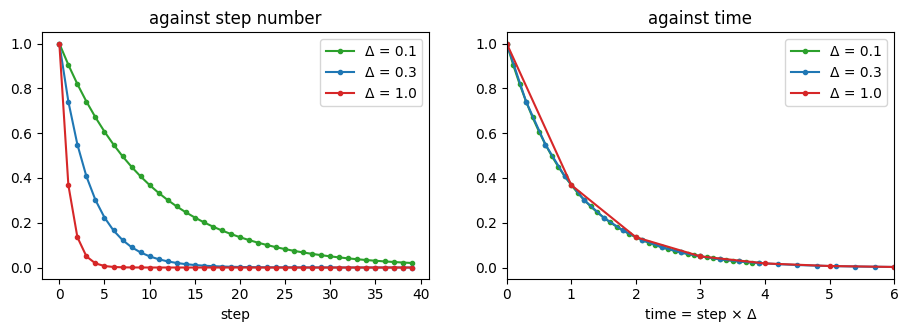

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for dt, c in [(0.1, "tab:green"), (0.3, "tab:blue"), (1.0, "tab:red")]:
    Ab, Bb = zoh(a_c, b_c, dt)
    k = np.arange(40)
    resp = Ab ** k
    ax[0].plot(k, resp, "o-", ms=3, color=c, label=f"Δ = {dt}")
    ax[1].plot(k * dt, resp, "o-", ms=3, color=c, label=f"Δ = {dt}")
ax[0].set_xlabel("step"); ax[0].set_title("against step number")
ax[1].set_xlabel("time = step × Δ"); ax[1].set_xlim(0, 6); ax[1].set_title("against time")
for a_ in ax: a_.legend()
plt.show()

### Why we see this

Against time the three sets of dots sit on one curve, e^(−t): it is one physical system sampled at three
rates. Against steps they differ: Δ decides how many *tokens* that one physical memory spans. This is why Δ
is the most important learnt number in an SSM layer, and why Mamba (Part D) makes it depend on the input:
a token that should be remembered can ask for a small Δ, and a token that should wipe the slate can ask for
a large one.

---
## Step 9 - Why not the obvious shortcut?

The simplest discretisation is Euler's: Ā = 1 + Δ·a.

> **Predict:** with a = −1, is Euler stable for Δ = 0.1? For Δ = 2.5?

In [9]:
for dt in [0.1, 1.0, 2.5]:
    euler = 1 + dt * a_c
    exact, _ = zoh(a_c, b_c, dt)
    print(f"dt = {dt:<4} Euler Abar = {euler:+.3f}  ({'stable' if abs(euler) < 1 else 'UNSTABLE'})   "
          f"exact Abar = {exact:.3f}")

dt = 0.1  Euler Abar = +0.900  (stable)   exact Abar = 0.905
dt = 1.0  Euler Abar = +0.000  (stable)   exact Abar = 0.368
dt = 2.5  Euler Abar = -1.500  (UNSTABLE)   exact Abar = 0.082


### Why we see this

For small Δ the two agree (0.900 vs 0.905). At Δ = 2.5 Euler gives −1.5: the state flips sign and grows by
half every step, a decaying system turned into an exploding one by a bad ruler. The exact rule never does
this. Published SSMs use the zero-order hold or the closely related bilinear rule for exactly this reason:
a learnt Δ can become large, and the layer must stay stable when it does.

---
# Part C - The same model, computed in parallel

---
## Step 10 - The recurrence is a convolution

Unroll the loop. With x₀ = 0:

y_t = C B̄ u_t + C Ā B̄ u_{t−1} + C Ā² B̄ u_{t−2} + …

So the output is the input convolved with one fixed kernel K = (C B̄, C Ā B̄, C Ā² B̄, …), as long as the
sequence. We build a 16-state diagonal SSM with memories from a few steps to a few hundred, compute its
kernel, and compare.

> **Predict:** how big is the largest difference between the loop and the convolution? 0.1? 1e-3? Smaller?

In [10]:
N, T = 16, 4096
rates = np.logspace(-2.5, 0, N)                  # decay rates from about 0.003 to 1
Abar_d, Bbar_d = zoh(-rates, np.ones(N), 1.0)    # diagonal SSM, one Abar per state number
C_d = rng.normal(size=N)
u = rng.normal(size=T)

def ssm_diag_loop(Abar, Bbar, C, u):
    x = np.zeros_like(Abar); y = np.empty(len(u))
    for i, ut in enumerate(u):
        x = Abar * x + Bbar * ut
        y[i] = C @ x
    return y

kernel = (C_d * Bbar_d) @ (Abar_d[:, None] ** np.arange(T)[None, :])   # K_j = sum_n C_n Abar_n^j Bbar_n

t0 = time.perf_counter(); y_loop = ssm_diag_loop(Abar_d, Bbar_d, C_d, u); t_loop = time.perf_counter() - t0
t0 = time.perf_counter()
L = 2 * T
y_fft = np.fft.irfft(np.fft.rfft(u, L) * np.fft.rfft(kernel, L), L)[:T]
t_fft = time.perf_counter() - t0
y_direct = np.convolve(u, kernel)[:T]

print("kernel length            :", kernel.shape[0])
print("max |loop - direct conv| :", f"{np.abs(y_loop - y_direct).max():.2e}")
print("max |loop - FFT conv|    :", f"{np.abs(y_loop - y_fft).max():.2e}")
print(f"time: Python loop {t_loop * 1000:.1f} ms, FFT convolution {t_fft * 1000:.2f} ms (this machine)")

kernel length            : 4096


max |loop - direct conv| : 1.60e-14
max |loop - FFT conv|    : 1.78e-14
time: Python loop 12.6 ms, FFT convolution 4.10 ms (this machine)


### Why we see this

The differences are at the level of floating-point rounding (around 1e-13 or smaller): the loop and the
convolution are **the same function**, written two ways. The loop needs T steps, each waiting for the one
before. The convolution has no waiting: every output can be computed at once, and an FFT does the whole
thing in about T·log T work. This is the S4 trick for training: compute the kernel, convolve the whole
sequence in parallel. At inference, when tokens arrive one at a time, switch back to the loop and keep only
the 16 state numbers. (Your timings will differ; the point is the shape of the work, not the milliseconds.)

---
## Step 11 - Look at the kernel

> **Predict:** the kernel is a sum of 16 decaying exponentials. Will it be short and spiky or long and
> smooth?

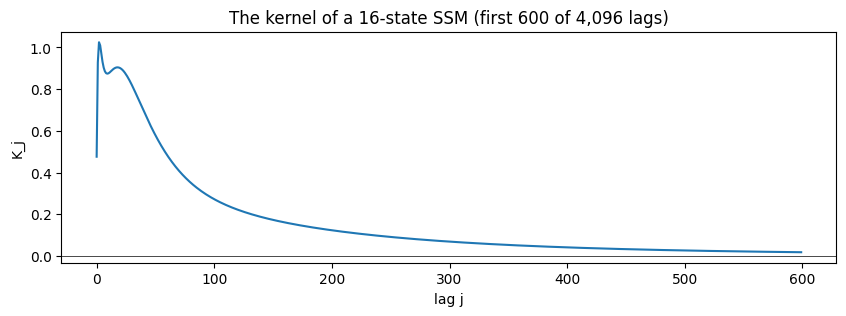

kernel weight still present at lag 1000: 0.00504


In [11]:
plt.figure(figsize=(10, 3))
plt.plot(kernel[:600], color="tab:blue", lw=1.5)
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("lag j"); plt.ylabel("K_j"); plt.title("The kernel of a 16-state SSM (first 600 of 4,096 lags)")
plt.show()
print("kernel weight still present at lag 1000:", f"{abs(kernel[1000]):.3g}")

### Why we see this

A long kernel built from only 16 × 3 = 48 numbers (Ā, B̄ and C per state). A convolutional layer with a
4,096-long kernel would need 4,096 free weights and would have no built-in idea that nearby lags should be
similar; the SSM gets a long, smooth, structured kernel cheaply. That is one honest way to see what S4 was:
**a very long convolution with a clever, compact parameterisation**.

---
## Step 12 - The parallel scan

The convolution trick needs the *same* Ā at every step. Part D will break that (Ā will depend on the input).
There is a second trick that survives: the recurrence x_t = a_t·x_{t−1} + b_t can be combined in pairs.
Two consecutive steps (a₁, b₁) then (a₂, b₂) equal one step (a₂a₁, a₂b₁ + b₂). Because this combining rule
is associative, all prefixes can be computed in log₂(T) rounds of fully parallel work.

> **Predict:** how many rounds for T = 4,096? Does the answer match the loop when every step has a
> different a_t?

In [12]:
def parallel_scan(a, b):
    """Inclusive scan for x_t = a_t x_{t-1} + b_t with x_{-1} = 0, in log2(T) vectorised rounds."""
    A_, B_ = a.copy(), b.copy()
    off, rounds = 1, 0
    while off < len(a):
        B_new = B_.copy(); A_new = A_.copy()
        B_new[off:] = A_[off:] * B_[:-off] + B_[off:]
        A_new[off:] = A_[off:] * A_[:-off]
        A_, B_ = A_new, B_new
        off *= 2; rounds += 1
    return B_, rounds

a_t = rng.uniform(0.5, 1.0, size=T)          # a different decay at every step
b_t = rng.normal(size=T)
x_seq = np.empty(T); x = 0.0
for i in range(T):
    x = a_t[i] * x + b_t[i]; x_seq[i] = x
x_par, rounds = parallel_scan(a_t, b_t)
print("rounds:", rounds, "  (log2 of", T, "=", np.log2(T), ")")
print("max |sequential - scan|:", f"{np.abs(x_seq - x_par).max():.2e}")

rounds: 12   (log2 of 4096 = 12.0 )
max |sequential - scan|: 1.78e-15


### Why we see this

12 rounds instead of 4,096 dependent steps, with the same answer to rounding error. This version does more
total arithmetic than the loop (about T·log₂T), and production kernels use smarter work-efficient scans, but
the principle is the one that matters: **a linear recurrence does not have to be computed one step at a
time**. Put a tanh inside the loop (a classic RNN, Chapter 19) and the pairing rule breaks; that is why the
linearity of SSMs is a feature, not a weakness.

---
# Part D - Selectivity: letting the input choose

---
## Step 13 - A task that needs a choice

Each sequence has 40 steps and two input channels: a **value** channel (random numbers) and a **marker**
channel (mostly 0, with a 1 at one to three random places). The answer, read at the very end, is the value
that came **right after the last marker**. A second marker means "forget the first one".

> **Predict:** what mean squared error does "always answer 0" get? (The values are standard normal.)

In [13]:
def make_marker_task(n, T=40, rng=rng):
    v = rng.normal(size=(n, T))
    m = np.zeros((n, T))
    target = np.empty(n)
    for i in range(n):
        k = rng.integers(1, 4)
        pos = np.sort(rng.choice(T - 1, size=k, replace=False))   # marker positions 0..T-2
        m[i, pos] = 1.0
        target[i] = v[i, pos[-1] + 1]                              # the value after the LAST marker
    return v, m, target

v_tr, m_tr, y_tr = make_marker_task(3000)
v_te, m_te, y_te = make_marker_task(1000)
print("shapes:", v_tr.shape, m_tr.shape, y_tr.shape)
print("baseline 'always 0' test MSE:", round(float(np.mean(y_te ** 2)), 3))

shapes: (3000, 40) (3000, 40) (3000,)
baseline 'always 0' test MSE: 0.954


---
## Step 14 - The best fixed SSM there could ever be

Any fixed (time-invariant) SSM, of **any** state size, produces at the last step a fixed weighted sum of all
past inputs: y_T = Σ_j K_j·u_{T−j} over both channels (Step 10). So instead of training one particular SSM,
we find the best possible kernel directly by least squares on the training set. No fixed SSM can do better
than this.

> **Predict:** will the best fixed filter get close to 0, or stay close to the baseline of about 1?

In [14]:
def lin_features(v, m):
    return np.hstack([v, m, np.ones((len(v), 1))])          # 40 value weights, 40 marker weights, a bias

w_best, *_ = np.linalg.lstsq(lin_features(v_tr, m_tr), y_tr, rcond=None)
pred_fixed = lin_features(v_te, m_te) @ w_best
print("best fixed SSM (any size) test MSE:", round(mse(pred_fixed, y_te), 3))

best fixed SSM (any size) test MSE:

 0.93


### Why we see this

Close to the baseline. A fixed filter must give each past position the same weight in every sequence, but
the position that matters moves from sequence to sequence. The best it can do is spread its weight towards
the later positions, where the last marker tends to fall, and that buys very little. The marker channel
does not help either: in a fixed filter the marker can only *add* to the output; it cannot *switch* which
value gets through. **A content-blind filter cannot decide what to keep.**

---
## Step 15 - A selective SSM: Δ depends on the input

One state number, the exact discretisation of Step 7 with a = −1, but now **Δ is computed from the input at
every step**:

* Δ_t = softplus(w · m_{t−1} + c)   (softplus keeps Δ positive)
* Ā_t = exp(−Δ_t),  state = Ā_t·state + (1 − Ā_t)·v_t

Small Δ: hold the state. Large Δ: flush it and write the current value. Δ looks at the marker one step back,
because the value to keep arrives one step after its marker. (Real Mamba blocks put a short convolution
before the SSM, which gives each step a view of its immediate neighbours in exactly this way.)

> **Predict:** which signs and sizes of w and c make the model hold most of the time and write only right
> after a marker?

In [15]:
softplus = lambda z: np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0)

def selective_ssm(v, m, w, c):
    m_prev = np.hstack([np.zeros((len(m), 1)), m[:, :-1]])   # marker one step back
    dt = softplus(w * m_prev + c)
    Abar = np.exp(-dt)
    x = np.zeros(len(v)); trace = []
    for t_ in range(v.shape[1]):
        x = Abar[:, t_] * x + (1 - Abar[:, t_]) * v[:, t_]
        trace.append(x.copy())
    return x, np.array(trace).T, dt

# "training": a coarse grid search over the two numbers, on the training set only
best = (np.inf, None, None)
for w in np.arange(0, 21, 1.0):
    for c in np.arange(-14, 3, 1.0):
        out, _, _ = selective_ssm(v_tr, m_tr, w, c)
        e = mse(out, y_tr)
        if e < best[0]:
            best = (e, w, c)
print(f"best on training set: w = {best[1]}, c = {best[2]}, train MSE = {best[0]:.2e}")
out_te, trace_te, dt_te = selective_ssm(v_te, m_te, best[1], best[2])
print("selective SSM test MSE:", f"{mse(out_te, y_te):.2e}")

best on training set: w = 20.0, c = -11.0, train MSE = 1.58e-07
selective SSM test MSE: 1.52e-07


### Why we see this

Error near zero, against about 1 for every fixed SSM, with **two** parameters. The search picks a very
negative c (with no marker, Δ = softplus(c) is about e^c, tiny, so the state holds for the whole sequence)
and a large w (right after a marker, Δ is large, Ā is near 0, the old state is flushed and the new value is
written). A second marker simply triggers a second flush. This is the gate of an LSTM (Chapter 20) arriving
in SSM form: the input decides how much of the past to keep.

---
## Step 16 - Watch it choose

> **Predict:** in the trace below, where will the state jump, and what will it do between jumps?

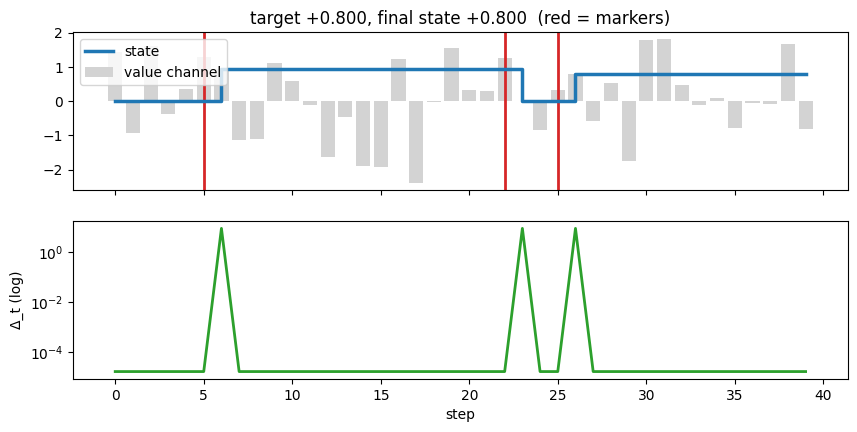

In [16]:
i = int(np.argmax(m_te.sum(axis=1) >= 2))     # an example with at least two markers
fig, ax = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
ax[0].bar(range(40), v_te[i], color="lightgray", label="value channel")
for p in np.where(m_te[i] == 1)[0]:
    ax[0].axvline(p, color="tab:red", lw=2)
ax[0].plot(range(40), trace_te[i], color="tab:blue", lw=2.5, drawstyle="steps-post", label="state")
ax[0].legend(loc="upper left"); ax[0].set_title(f"target {y_te[i]:+.3f}, final state {out_te[i]:+.3f}  (red = markers)")
ax[1].semilogy(range(40), dt_te[i], color="tab:green", lw=2); ax[1].set_ylabel("Δ_t (log)")
ax[1].set_xlabel("step"); plt.show()

### Why we see this

Δ sits near zero almost everywhere and leaps by many orders of magnitude on the step after each marker. The
state is flat (holding) between those steps and jumps to the new value at each one. The model has learnt a
tiny program: *wait, grab, wait, grab again, report.* A fixed SSM cannot express it because its Δ is the
same at every step.

---
## Step 17 - The price: no more convolution, but the scan still works

Because Ā_t now changes from step to step, there is no single kernel and Step 10's FFT trick is gone. Step
12's scan does not care.

> **Predict:** does the parallel scan reproduce the selective SSM's final states exactly?

In [17]:
m_prev = np.hstack([np.zeros((len(m_te), 1)), m_te[:, :-1]])
Abar_t = np.exp(-softplus(best[1] * m_prev + best[2]))
finals = np.array([parallel_scan(Abar_t[k], (1 - Abar_t[k]) * v_te[k])[0][-1] for k in range(len(v_te))])
print("max |loop - scan| over 1,000 test sequences:", f"{np.abs(finals - out_te).max():.2e}")

max |loop - scan| over 1,000 test sequences: 3.55e-15


### Why we see this

Identical to rounding error. This is the deal Mamba (2023) made: give up the convolution, keep linearity in
the state, compute training with a hardware-aware scan, and in exchange let Δ (and also B and C) depend on
each token. In the real layer every channel has its own Δ, the state per channel has N numbers (16 is a
common choice), and all of it is learnt by gradient descent rather than a grid search.

---
# Part E - A fixed-size state versus the whole history

---
## Step 18 - How much can N numbers remember?

Feed white noise for 256 steps into an N-number linear state. Then ask: how well can a linear read-out
recover the input from j steps ago, for every j? The score for each lag is R² (1 = perfect recall, 0 = no
idea). For a linear state these scores can be computed exactly, without simulation.

> **Predict:** for N = 16, what do the 256 scores add up to, at most?

shift register: sum of R^2 over 256 lags = 16.00   (recalls lags 0-15 perfectly)
fading memories: sum of R^2 over 256 lags = 15.00
whole history  : sum of R^2 over 256 lags = 256  (but it stores 256 numbers)


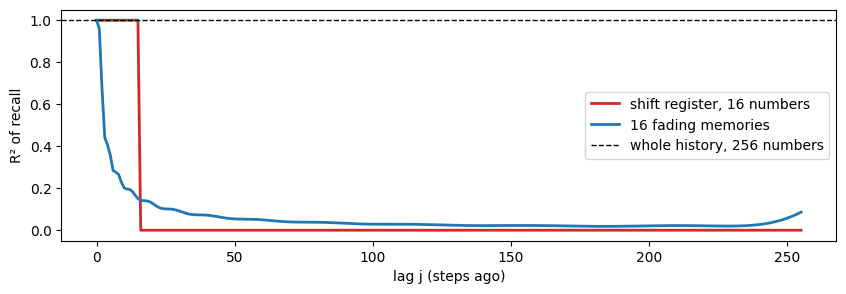

In [18]:
def recall_profile(A, B, T=256):
    cols = []; x = B.copy()
    for _ in range(T):
        cols.append(x.copy()); x = A @ x
    M = np.array(cols).T                         # state = M @ (u_T, u_{T-1}, ...)
    G = np.linalg.pinv(M @ M.T, rcond=1e-12)
    return np.einsum("nj,nk,kj->j", M, G, M)     # R^2 for each lag j

Nn = 16
shift = np.eye(Nn, k=-1); e1 = np.zeros(Nn); e1[0] = 1.0     # a shift register: keeps the last 16 inputs
decays = np.exp(-np.logspace(-2, 0, Nn))                        # 16 fading memories, slow to fast
r2_shift = recall_profile(shift, e1)
r2_fade = recall_profile(np.diag(decays), np.ones(Nn))
print(f"shift register: sum of R^2 over 256 lags = {r2_shift.sum():.2f}   (recalls lags 0-15 perfectly)")
print(f"fading memories: sum of R^2 over 256 lags = {r2_fade.sum():.2f}")
print(f"whole history  : sum of R^2 over 256 lags = 256  (but it stores 256 numbers)")

plt.figure(figsize=(10, 3))
plt.plot(r2_shift, color="tab:red", lw=2, label="shift register, 16 numbers")
plt.plot(r2_fade, color="tab:blue", lw=2, label="16 fading memories")
plt.axhline(1, color="k", ls="--", lw=1, label="whole history, 256 numbers")
plt.xlabel("lag j (steps ago)"); plt.ylabel("R² of recall"); plt.legend(); plt.show()

### Why we see this

The scores never add up to more than N = 16. The shift register spends its budget on a perfect window of the
last 16 inputs and knows nothing older. The fading memories spread the same budget thinly over a much longer
past, recalling nothing perfectly (and with close eigenvalues the budget is partly wasted, so the sum
falls below 16). Storing the whole history recalls every lag perfectly, at the price of memory that grows
with the sequence. **A fixed-size state is a lossy summary, always.** Design (HiPPO, selectivity) decides
*what* it keeps, not whether it loses something.

---
## Step 19 - Memory at inference: state vs cache

A transformer keeps every past key and value (the KV cache of Chapter 23): 2·T·d numbers per layer. An SSM
layer keeps d channels × N state numbers, whatever T is. Take an illustrative layer width d = 1,024 and N = 16.

> **Predict:** at how many tokens does the cache pass the SSM state? How many times bigger is it at 100,000?

In [19]:
d_model, N_state = 1024, 16
ssm_state = d_model * N_state
print(f"SSM state per layer: {ssm_state:,} numbers, at any length")
for T_ in [8, 1_000, 10_000, 100_000]:
    cache = 2 * T_ * d_model
    print(f"  T = {T_:>7,}: KV cache {cache:>12,} numbers = {cache / ssm_state:>8,.1f} x the SSM state")

SSM state per layer: 16,384 numbers, at any length
  T =       8: KV cache       16,384 numbers =      1.0 x the SSM state
  T =   1,000: KV cache    2,048,000 numbers =    125.0 x the SSM state
  T =  10,000: KV cache   20,480,000 numbers =  1,250.0 x the SSM state
  T = 100,000: KV cache  204,800,000 numbers = 12,500.0 x the SSM state


### Why we see this

The two are equal at T = 8 tokens; after that the cache grows by 2,048 numbers per token and is 12,500 times
the state at 100,000 tokens. That is the SSM's practical selling point for long streams (audio, genomes,
sensor logs). Step 18 is the bill: the cache can answer "what exactly was token 31,337?", the state can only
answer what it chose to keep.

---
## Step 20 - The exact-recall test, side by side

One last head-to-head on a task that needs exact recall of *several* things: memorise 32 random values,
then recall any one of them by position. Compare a 16-number state with a 32-number cache.

> **Predict:** average R² over the 32 positions for each.

In [20]:
T_rec = 32
r2_state = recall_profile(np.diag(decays), np.ones(Nn), T=T_rec)
r2_shift32 = recall_profile(shift, e1, T=T_rec)
print(f"16 fading memories : mean R^2 over 32 positions = {r2_state.mean():.3f}")
print(f"16-slot shift reg. : mean R^2 over 32 positions = {r2_shift32.mean():.3f}")
print(f"32-number cache    : mean R^2 over 32 positions = 1.000")

16 fading memories : mean R^2 over 32 positions = 0.312
16-slot shift reg. : mean R^2 over 32 positions = 0.500
32-number cache    : mean R^2 over 32 positions = 1.000


### Why we see this

Any 16-number linear state averages at most 16/32 = 0.5 here, however clever its matrix, because the R²
scores cannot add up to more than 16. The cache scores 1.0 because it stores everything. This is the
honest core of the "SSM vs attention" debate: a compact state is cheap and fast; a full history is exact.
Hybrids that mix a few attention layers into an SSM stack are one attempt to get both.

---
## Trials: change one thing at a time

| # | Change | Predict first | Observe |
|---|---|---|---|
| 1 | Step 3: noise 0.4 → 1.0 | Does the best a in Step 4 move up or down? | |
| 2 | Step 6: r = 0.95 → 1.01 in the ringing matrix | What does the purple curve do? | |
| 3 | Step 7: a = −1 → −10 with Δ = 0.1 | Ā? Memory in steps? | |
| 4 | Step 10: N = 16 → 2 | Does the loop still equal the convolution? What does the kernel look like? | |
| 5 | Step 13: put the value **on** the marker step, not after it, and use m_t instead of m_{t−1} | Does the selective SSM still solve it? Does the fixed one? | |
| 6 | Step 15: fix w = 0 and search only c | Which test MSE do you get, and why is it like Step 14? | |
| 7 | Step 13: T = 40 → 400 | Does the selective SSM need a more negative c? Why? | |
| 8 | Step 18: N = 16 → 64 | What is the new ceiling on the sum of R²? | |

## Exercises

1. **Two memories, one state.** Change the task so the answer is the *sum* of the values after the first and
   the last marker. Can a one-number selective state do it? What is the smallest state that can?
2. **Make B selective too.** In Step 15 the write strength is tied to the forget strength (1 − Ā). Give the
   write its own input-dependent gate and design a task where that freedom matters.
3. **Bilinear discretisation.** Implement Ā = (1 + Δa/2)/(1 − Δa/2) and compare it with the zero-order hold
   of Step 7 for Δ = 0.1, 1 and 10. Is it always stable for a < 0?
4. **Kernel by FFT.** For a diagonal SSM the kernel's Fourier transform has a closed form. Derive it for one
   state number and check it against `np.fft.rfft(kernel)`.
5. **Work-efficient scan.** Step 12's scan does about T·log₂T work. Look up the two-sweep (up-sweep,
   down-sweep) scan and implement it with about 2T work. Count rounds and operations.
6. **Linear attention as an SSM.** Chapter 25 ends with causal linear attention as S ← S + φ(k)vᵀ. Write it
   in the form state = A·state + B·input. What are A and B? What would a selective A add?

## Cheat sheet

| Idea | One line |
|---|---|
| The model | x ← A·x + B·u, y = C·x; linear in x, no tanh in the loop |
| Memory | eigenvalues of A: \|λ\| < 1 fades (half-life ln 0.5 / ln \|λ\|), = 1 holds, > 1 explodes; complex λ rings |
| Discretisation | Ā = exp(Δ·a), B̄ = (Ā − 1)/a · b; small Δ holds, large Δ resets; stable for any Δ when a < 0 |
| Euler | Ā = 1 + Δa: fine for small Δ, unstable for large Δ |
| Convolution view | fixed A, B, C ⇒ y = K ∗ u with K_j = C Ā^j B̄: parallel training (S4) |
| Scan view | x_t = a_t x_{t−1} + b_t combines associatively: log₂T parallel rounds, works when a_t varies |
| Selective SSM | Δ (and B, C) computed from the input: can hold, write or flush; no convolution, scan instead (Mamba) |
| Fixed state | N numbers recall at most N numbers' worth of history (sum of R² ≤ N); a cache recalls everything |
| Inference memory | SSM: d·N numbers per layer, constant; KV cache: 2·T·d, growing |